In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

crime = pd.read_csv("Crime_Data_from_2020_to_Present.csv")

## Data Exploration

In [2]:
crime.head()

,DR_NO,Date Rptd,DATE OCC,TIME OCC,AREA,AREA NAME,Rpt Dist No,Part 1-2,Crm Cd,Crm Cd Desc,...,Status,Status Desc,Crm Cd 1,Crm Cd 2,Crm Cd 3,Crm Cd 4,LOCATION,Cross Street,LAT,LON
0,190326475,3/1/2020 0:00,3/1/2020 0:00,2130,7,Wilshire,784,1,510,VEHICLE - STOLEN,...,AA,Adult Arrest,510.0,998.0,NaN,NaN,1900 S LONGWOOD AV,NaN,34.0375,-118.3506
1,200106753,2/9/2020 0:00,2/8/2020 0:00,1800,1,Central,182,1,330,BURGLARY FROM VEHICLE,...,IC,Invest Cont,330.0,998.0,NaN,NaN,1000 S FLOWER ST,NaN,34.0444,-118.2628
2,200320258,11/11/2020 0:00,11/4/2020 0:00,1700,3,Southwest,356,1,480,BIKE - STOLEN,...,IC,Invest Cont,480.0,NaN,NaN,NaN,1400 W 37TH ST,NaN,34.0210,-118.3002
3,200907217,5/10/2023 0:00,3/10/2020 0:00,2037,9,Van Nuys,964,1,343,SHOPLIFTING-GRAND THEFT ($950.01 & OVER),...,IC,Invest Cont,343.0,NaN,NaN,NaN,14000 RIVERSIDE DR,NaN,34.1576,-118.4387
4,200412582,9/9/2020 0:00,9/9/2020 0:00,630,4,Hollenbeck,413,1,510,VEHICLE - STOLEN,...,IC,Invest Cont,510.0,NaN,NaN,NaN,200 E AVENUE 28,NaN,34.0820,-118.2130


In [3]:
crime.shape

(1005198, 28)

In [4]:
crime.columns

Index(['DR_NO', 'Date Rptd', 'DATE OCC', 'TIME OCC', 'AREA', 'AREA NAME',
       'Rpt Dist No', 'Part 1-2', 'Crm Cd', 'Crm Cd Desc', 'Mocodes',
       'Vict Age', 'Vict Sex', 'Vict Descent', 'Premis Cd', 'Premis Desc',
       'Weapon Used Cd', 'Weapon Desc', 'Status', 'Status Desc', 'Crm Cd 1',
       'Crm Cd 2', 'Crm Cd 3', 'Crm Cd 4', 'LOCATION', 'Cross Street', 'LAT',
       'LON'],
      dtype='str')

In [5]:
crime.info()

<class 'pandas.DataFrame'>
RangeIndex: 1005198 entries, 0 to 1005197
Data columns (total 28 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   DR_NO           1005198 non-null  int64  
 1   Date Rptd       1005198 non-null  str    
 2   DATE OCC        1005198 non-null  str    
 3   TIME OCC        1005198 non-null  int64  
 4   AREA            1005198 non-null  int64  
 5   AREA NAME       1005198 non-null  str    
 6   Rpt Dist No     1005198 non-null  int64  
 7   Part 1-2        1005198 non-null  int64  
 8   Crm Cd          1005198 non-null  int64  
 9   Crm Cd Desc     1005198 non-null  str    
 10  Mocodes         853438 non-null   str    
 11  Vict Age        1005198 non-null  int64  
 12  Vict Sex        860416 non-null   str    
 13  Vict Descent    860404 non-null   str    
 14  Premis Cd       1005182 non-null  float64
 15  Premis Desc     1004610 non-null  str    
 16  Weapon Used Cd  327280 non-null   float64
 17  

In [6]:
crime.isnull().sum()[crime.isnull().sum() > 0]

Mocodes            151760
Vict Sex           144782
Vict Descent       144794
Premis Cd              16
Premis Desc           588
Weapon Used Cd     677918
Weapon Desc        677918
Status                  1
Crm Cd 1               11
Crm Cd 2           936039
Crm Cd 3          1002884
Crm Cd 4          1005134
Cross Street       850955
dtype: int64

In [7]:
crime.nunique()

DR_NO             1005198
Date Rptd            1906
DATE OCC             1901
TIME OCC             1439
AREA                   21
AREA NAME              21
Rpt Dist No          1210
Part 1-2                2
Crm Cd                140
Crm Cd Desc           140
Mocodes            310956
Vict Age              104
Vict Sex                5
Vict Descent           20
Premis Cd             314
Premis Desc           306
Weapon Used Cd         79
Weapon Desc            79
Status                  6
Status Desc             6
Crm Cd 1              142
Crm Cd 2              126
Crm Cd 3               38
Crm Cd 4                6
LOCATION            66567
Cross Street        10414
LAT                  5426
LON                  4982
dtype: int64

In [8]:
crime.duplicated().sum()

np.int64(0)

In [9]:
pd.options.display.float_format = "{:,.2f}".format
crime.describe()

,DR_NO,TIME OCC,AREA,Rpt Dist No,Part 1-2,Crm Cd,Vict Age,Premis Cd,Weapon Used Cd,Crm Cd 1,Crm Cd 2,Crm Cd 3,Crm Cd 4,LAT,LON
count,"1,005,198.00","1,005,198.00","1,005,198.00","1,005,198.00","1,005,198.00","1,005,198.00","1,005,198.00","1,005,182.00","327,280.00","1,005,187.00","69,159.00","2,314.00",64.00,"1,005,198.00","1,005,198.00"
mean,"220,227,677.87","1,339.91",10.69,"1,115.56",1.40,500.15,28.91,305.62,363.95,499.91,958.11,984.02,991.22,34.00,-118.09
std,"13,202,822.08",651.05,6.11,611.17,0.49,205.26,21.99,219.32,123.74,205.06,110.35,52.35,27.07,1.61,5.58
min,817.00,1.00,1.00,101.00,1.00,110.00,-4.00,101.00,101.00,110.00,210.00,310.00,821.00,0.00,-118.67
25%,"210,616,927.25",900.00,5.00,587.00,1.00,331.00,0.00,101.00,311.00,331.00,998.00,998.00,998.00,34.01,-118.43
50%,"220,916,044.00","1,420.00",11.00,"1,139.00",1.00,442.00,30.00,203.00,400.00,442.00,998.00,998.00,998.00,34.06,-118.32
75%,"231,110,516.25","1,900.00",16.00,"1,613.00",2.00,626.00,44.00,501.00,400.00,626.00,998.00,998.00,998.00,34.16,-118.27
max,"252,104,146.00","2,359.00",21.00,"2,199.00",2.00,956.00,120.00,976.00,516.00,956.00,999.00,999.00,999.00,34.33,0.00


In [10]:
crime[crime["Vict Age"] <= 0]["Vict Age"].value_counts()

Vict Age
 0    269377
-1        99
-2        28
-3         6
-4         3
Name: count, dtype: int64

In [11]:
crime[crime["Vict Age"] >= 100]["Vict Age"].value_counts()

Vict Age
120    1
Name: count, dtype: int64

In [12]:
crime[crime["LAT"] == 0]["LAT"].value_counts()

LAT
0.00    2240
Name: count, dtype: int64

In [13]:
crime[crime["LON"] == 0]["LON"].value_counts()

LON
0.00    2240
Name: count, dtype: int64

In [14]:
crime[(crime["LAT"] == 0) & (crime["LON"] == 0)].shape[0]

2240

In [15]:
placeholders = [
    "NA",
    "na",
    "Na",
    "N/A",
    "n/a",
    "N.A.",
    "none",
    "None",
    "NONE",
    "missing",
    "Missing",
    "unknown",
    "Unknown",
    "UNK",
    "undefined",
    "-",
    "?",
    "x",
    "X",
    "",
    " ",
    "   ",
]
missing_counts = crime.isin(placeholders).sum()[crime.isin(placeholders).sum() > 0]

missing_counts

Vict Sex         97787
Vict Descent    106701
Status Desc          7
LOCATION             1
dtype: int64

In [16]:
crime["Vict Sex"].value_counts()

Vict Sex
M    403916
F    358599
X     97786
H       114
-         1
Name: count, dtype: int64

In [17]:
crime["Vict Descent"].value_counts()

Vict Descent
H    296437
W    201451
B    135823
X    106699
O     78010
A     21340
K      5991
F      4838
C      4631
J      1586
V      1195
I      1015
Z       577
P       288
U       221
D        91
L        77
G        74
S        58
-         2
Name: count, dtype: int64

In [18]:
crime["Status Desc"].value_counts()

Status Desc
Invest Cont     803946
Adult Other     109255
Adult Arrest     86877
Juv Arrest        3249
Juv Other         1864
UNK                  7
Name: count, dtype: int64

In [19]:
crime["LOCATION"].value_counts()

LOCATION
800 N  ALAMEDA                      ST      2598
700 S  FIGUEROA                     ST      1711
100    THE GROVE                    DR      1688
10200    SANTA MONICA                 BL    1657
6TH                          ST             1585
                                            ... 
9500    LA CIENEGA                   BL        1
1800 E  MARTIN LUTHER KING JR        BL        1
12200    ART                          ST       1
300 E  HARRY BRIDGE                 BL         1
2400 S  SIGNAL                       ST        1
Name: count, Length: 66567, dtype: int64

In [20]:
crime[crime["LOCATION"].isin(placeholders)]

,DR_NO,Date Rptd,DATE OCC,TIME OCC,AREA,AREA NAME,Rpt Dist No,Part 1-2,Crm Cd,Crm Cd Desc,...,Status,Status Desc,Crm Cd 1,Crm Cd 2,Crm Cd 3,Crm Cd 4,LOCATION,Cross Street,LAT,LON
166567,201600732,7/25/2020 0:00,7/25/2020 0:00,400,16,Foothill,1677,1,121,"RAPE, FORCIBLE",...,IC,Invest Cont,121.00,NaN,NaN,NaN,UNK,LOCATION,34.22,-118.35


## Data Cleaning

In [21]:
columns_to_drop = [
    "AREA",
    "Rpt Dist No",
    "Part 1-2",
    "Crm Cd",
    "Mocodes",
    "Premis Cd",
    "Premis Desc",
    "Weapon Used Cd",
    "Weapon Desc",
    "Status",
    "Crm Cd 1",
    "Crm Cd 2",
    "Crm Cd 3",
    "Crm Cd 4",
    "LOCATION",
    "Cross Street"
]

crime = crime.drop(columns=columns_to_drop)

In [22]:
crime.columns

Index(['DR_NO', 'Date Rptd', 'DATE OCC', 'TIME OCC', 'AREA NAME',
       'Crm Cd Desc', 'Vict Age', 'Vict Sex', 'Vict Descent', 'Status Desc',
       'LAT', 'LON'],
      dtype='str')

In [23]:
crime.replace("-", np.nan, inplace=True)

,DR_NO,Date Rptd,DATE OCC,TIME OCC,AREA NAME,Crm Cd Desc,Vict Age,Vict Sex,Vict Descent,Status Desc,LAT,LON
0,190326475,3/1/2020 0:00,3/1/2020 0:00,2130,Wilshire,VEHICLE - STOLEN,0,M,O,Adult Arrest,34.04,-118.35
1,200106753,2/9/2020 0:00,2/8/2020 0:00,1800,Central,BURGLARY FROM VEHICLE,47,M,O,Invest Cont,34.04,-118.26
2,200320258,11/11/2020 0:00,11/4/2020 0:00,1700,Southwest,BIKE - STOLEN,19,X,X,Invest Cont,34.02,-118.30
3,200907217,5/10/2023 0:00,3/10/2020 0:00,2037,Van Nuys,SHOPLIFTING-GRAND THEFT ($950.01 & OVER),19,M,O,Invest Cont,34.16,-118.44
4,200412582,9/9/2020 0:00,9/9/2020 0:00,630,Hollenbeck,VEHICLE - STOLEN,0,NaN,NaN,Invest Cont,34.08,-118.21
...,...,...,...,...,...,...,...,...,...,...,...,...
1005193,250304214,2/23/2025 0:00,2/21/2025 0:00,1530,Southwest,VEHICLE - STOLEN,0,NaN,NaN,Invest Cont,34.02,-118.29
1005194,250304203,2/20/2025 0:00,2/13/2025 0:00,2100,Southwest,"VEHICLE, STOLEN - OTHER (MOTORIZED SCOOTERS, B...",0,NaN,NaN,Invest Cont,34.03,-118.29
1005195,250504051,1/14/2025 0:00,1/14/2025 0:00,1250,Harbor,ROBBERY,15,F,H,Invest Cont,33.80,-118.31
1005196,251604136,2/27/2025 0:00,2/27/2025 0:00,1550,Foothill,VEHICLE - STOLEN,0,NaN,NaN,Adult Arrest,34.24,-118.39


In [24]:
crime["Vict Descent"].value_counts(dropna=False)

Vict Descent
H      296437
W      201451
NaN    144796
B      135823
X      106699
O       78010
A       21340
K        5991
F        4838
C        4631
J        1586
V        1195
I        1015
Z         577
P         288
U         221
D          91
L          77
G          74
S          58
Name: count, dtype: int64

In [25]:
crime["Vict Sex"] = crime["Vict Sex"].replace("H", np.nan)

In [26]:
crime["Vict Sex"] = crime["Vict Sex"].replace("X", np.nan)

In [27]:
crime["Vict Sex"].value_counts(dropna=False)

Vict Sex
M      403916
F      358599
NaN    242683
Name: count, dtype: int64

In [28]:
crime.replace("UNK", np.nan, inplace=True)

,DR_NO,Date Rptd,DATE OCC,TIME OCC,AREA NAME,Crm Cd Desc,Vict Age,Vict Sex,Vict Descent,Status Desc,LAT,LON
0,190326475,3/1/2020 0:00,3/1/2020 0:00,2130,Wilshire,VEHICLE - STOLEN,0,M,O,Adult Arrest,34.04,-118.35
1,200106753,2/9/2020 0:00,2/8/2020 0:00,1800,Central,BURGLARY FROM VEHICLE,47,M,O,Invest Cont,34.04,-118.26
2,200320258,11/11/2020 0:00,11/4/2020 0:00,1700,Southwest,BIKE - STOLEN,19,NaN,X,Invest Cont,34.02,-118.30
3,200907217,5/10/2023 0:00,3/10/2020 0:00,2037,Van Nuys,SHOPLIFTING-GRAND THEFT ($950.01 & OVER),19,M,O,Invest Cont,34.16,-118.44
4,200412582,9/9/2020 0:00,9/9/2020 0:00,630,Hollenbeck,VEHICLE - STOLEN,0,NaN,NaN,Invest Cont,34.08,-118.21
...,...,...,...,...,...,...,...,...,...,...,...,...
1005193,250304214,2/23/2025 0:00,2/21/2025 0:00,1530,Southwest,VEHICLE - STOLEN,0,NaN,NaN,Invest Cont,34.02,-118.29
1005194,250304203,2/20/2025 0:00,2/13/2025 0:00,2100,Southwest,"VEHICLE, STOLEN - OTHER (MOTORIZED SCOOTERS, B...",0,NaN,NaN,Invest Cont,34.03,-118.29
1005195,250504051,1/14/2025 0:00,1/14/2025 0:00,1250,Harbor,ROBBERY,15,F,H,Invest Cont,33.80,-118.31
1005196,251604136,2/27/2025 0:00,2/27/2025 0:00,1550,Foothill,VEHICLE - STOLEN,0,NaN,NaN,Adult Arrest,34.24,-118.39


In [29]:
crime["Status Desc"].value_counts(dropna=False)

Status Desc
Invest Cont     803946
Adult Other     109255
Adult Arrest     86877
Juv Arrest        3249
Juv Other         1864
NaN                  7
Name: count, dtype: int64

In [30]:
crime.loc[crime["Vict Age"] < 0, "Vict Age"] = np.nan

In [31]:
crime[crime["Vict Age"] < 0]["Vict Age"].value_counts()

Series([], Name: count, dtype: int64)

In [32]:
crime["LAT"] = crime["LAT"].replace(0, np.nan)

In [33]:
crime["LON"] = crime["LON"].replace(0, np.nan)

In [34]:
crime[(crime["LAT"] == 0) & (crime["LON"] == 0)].shape[0]

0

In [35]:
crime["Date Rptd"] = pd.to_datetime(crime["Date Rptd"])
crime["DATE OCC"] = pd.to_datetime(crime["DATE OCC"])
crime["TIME OCC"] = crime["TIME OCC"].astype(str).str.zfill(4)
crime["TIME OCC"] = pd.to_datetime(crime["TIME OCC"], format="%H%M").dt.hour

In [36]:
crime.dtypes

DR_NO                    int64
Date Rptd       datetime64[us]
DATE OCC        datetime64[us]
TIME OCC                 int32
AREA NAME                  str
Crm Cd Desc                str
Vict Age               float64
Vict Sex                   str
Vict Descent               str
Status Desc                str
LAT                    float64
LON                    float64
dtype: object

In [37]:
crime["year"] = crime["DATE OCC"].dt.year
crime["year"].value_counts().sort_index()

year
2020    199847
2021    209875
2022    235258
2023    232350
2024    127574
2025       294
Name: count, dtype: int64

In [38]:
crime = crime[crime["year"].between(2020, 2023)]

In [39]:
crime["year"].value_counts().sort_index()

year
2020    199847
2021    209875
2022    235258
2023    232350
Name: count, dtype: int64

In [40]:
crime["Vict Descent"] = crime["Vict Descent"].replace("X", np.nan)

In [41]:
ethnicity_mapping = {
    "A": "Other Asian",
    "B": "Black",
    "C": "Chinese",
    "D": "Cambodian",
    "F": "Filipino",
    "G": "Guamanian",
    "H": "Hispanic/Latin/Mexican",
    "I": "American Indian/Alaskan Native",
    "J": "Japanese",
    "K": "Korean",
    "L": "Laotian",
    "O": "Other",
    "P": "Pacific Islander",
    "S": "Samoan",
    "U": "Hawaiian",
    "V": "Vietnamese",
    "W": "White",
    "Z": "Asian Indian",
}

crime["Vict Descent"] = crime["Vict Descent"].replace(ethnicity_mapping)

In [42]:
crime["Vict Descent"].value_counts(dropna=False)

Vict Descent
Hispanic/Latin/Mexican            267795
NaN                               202117
White                             178474
Black                             124097
Other                              69458
Other Asian                        19247
Korean                              4796
Filipino                            3754
Chinese                             3477
Japanese                            1236
Vietnamese                           929
American Indian/Alaskan Native       839
Asian Indian                         452
Pacific Islander                     238
Hawaiian                             175
Cambodian                             74
Guamanian                             64
Laotian                               59
Samoan                                49
Name: count, dtype: int64

In [43]:
bins = [0, 17, 29, 39, 49, 59, 69, 79, 89, 150]
labels = ["Under 18", "18-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80-89", "90+"]
crime["age_group"] = pd.cut(crime["Vict Age"], bins=bins, labels=labels)
crime["age_group"] = crime["age_group"].cat.add_categories(["Non-Individual"])
crime.loc[crime["Vict Age"] == 0, "age_group"] = "Non-Individual"

In [44]:
crime["age_group"].value_counts(dropna=False)

age_group
Non-Individual    218450
18-29             173903
30-39             173884
40-49             116558
50-59              89002
60-69              53532
Under 18           23471
70-79              20924
80-89               5996
90+                 1474
NaN                  136
Name: count, dtype: int64

In [45]:
bins = [-1, 5, 11, 16, 23]
labels = ["Night", "Morning", "Afternoon", "Evening"]
crime["time_of_day"] = pd.cut(crime["TIME OCC"], bins=bins, labels=labels)

In [46]:
crime["time_of_day"].value_counts(dropna=False)

time_of_day
Evening      323843
Afternoon    234352
Morning      182827
Night        136308
Name: count, dtype: int64

In [48]:
def categorise_crime(desc):
  desc = str(desc).upper()

  if any(
      kw in desc
      for kw in [
          "ASSAULT",
          "BATTER",
          "ROBB",
          "HOMICID",
          "KIDNAP",
          "SHOT",
          "FIREARM",
          "MANSLAUGHTER",
          "THREAT",
          "STALK",
          "ABUSE",
          "NEGLECT"
      ]
  ):
    return "Violence"
      
  elif any(
      kw in desc
      for kw in [
          "THEFT",
          "STOLE",
          "BURGLAR",
          "SHOPLIFT",
          "PURSE",
          "PICKPOCKET",
          "SNATCH",
          "DUMP",
          "VEHIC",
          "BIKE",
          "BICYCLE",
          "BOAT",
          "VESSEL",
          "CAR"
      ]
  ):
    return "Property"

  elif any(
      kw in desc 
      for kw in [
          "VANDAL",
          "DAMAGE",
          "ARSON"
      ]
  ):
    return "Vandalism"

  elif any(
      kw in desc
      for kw in [
          "FRAUD",
          "FORGE",
          "EMBEZZLE",
          "BUNCO",
          "COUNTERFEIT",
          "EXTORT",
          "WORTH",
          "IDENT",
          "CREDIT",
          "CHECK",
          "CHEQUE"
      ]
  ):
    return "Finance"

  elif any(
      kw in desc
      for kw in [
          "RAP",
          "SEX",
          "LEWD",
          "SODOM",
          "ORAL",
          "INDEC",
          "PIMP",
          "PANDER",
          "INCEST",
          "PEEP",
          "LASCIVIOUS"
      ]
  ):
    return "Sex Offences"

  elif any(
      kw in desc
      for kw in [
          "TRESPASS",
          "RESTRAIN",
          "COURT",
          "DISTURB",
          "RESIST",
          "BOMB"
      ]
  ):
    return "Public Order"

  else:
    return "Other"

In [62]:
crime["crime_category"] = crime["Crm Cd Desc"].apply(categorise_crime)

In [63]:
crime["crime_category"].value_counts()

crime_category
Property        463882
Violence        251636
Vandalism        78535
Public Order     35591
Other            26488
Sex Offences     18809
Finance           2389
Name: count, dtype: int64

## Data Analysis

### How has reported crime changed over time?

In [51]:
crime_2020_2023 = crime[crime["DATE OCC"].dt.year.between(2020, 2023)]
crime_2020_2023["Year"] = crime_2020_2023["DATE OCC"].dt.year
crime_2020_2023["Month"] = crime_2020_2023["DATE OCC"].dt.month

monthly_crimes = crime_2020_2023.groupby([
    crime_2020_2023["DATE OCC"].dt.year,
    crime_2020_2023["DATE OCC"].dt.month
]).size()

monthly_crimes = (
    crime_2020_2023
    .groupby(["Year", "Month"])
    .size()
    .reset_index(name="Crime Count")
)

monthly_crimes

,Year,Month,Crime Count
0,2020,1,18576
1,2020,2,17284
2,2020,3,16188
3,2020,4,15706
4,2020,5,17230
5,2020,6,17060
6,2020,7,17158
7,2020,8,16902
8,2020,9,15658
9,2020,10,16510


In [52]:
monthly_crimes = monthly_crimes.pivot(
    index="Month",
    columns="Year",
    values="Crime Count"
)

monthly_crimes

Year,2020,2021,2022,2023
Month,,,,
1,18576,16636,18567,19972
2,17284,15440,17750,18489
3,16188,16354,19745,19214
4,15706,16091,19837,18937
5,17230,17020,20467,18910
6,17060,17182,20273,18743
7,17158,18690,20009,19934
8,16902,18398,20144,20082
9,15658,18386,19341,19321


### What are the most commonly reported crime types?

In [53]:
print(crime_2020_2023["Crm Cd Desc"].value_counts().to_string())

Crm Cd Desc
VEHICLE - STOLEN                                            93675
BATTERY - SIMPLE ASSAULT                                    69421
THEFT OF IDENTITY                                           56216
BURGLARY FROM VEHICLE                                       53990
BURGLARY                                                    53411
VANDALISM - FELONY ($400 & OVER, ALL CHURCH VANDALISMS)     53141
ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT              49828
THEFT PLAIN - PETTY ($950 & UNDER)                          44899
INTIMATE PARTNER - SIMPLE ASSAULT                           43717
THEFT FROM MOTOR VEHICLE - PETTY ($950 & UNDER)             33702
THEFT FROM MOTOR VEHICLE - GRAND ($950.01 AND OVER)         31318
ROBBERY                                                     29813
THEFT-GRAND ($950.01 & OVER)EXCPT,GUNS,FOWL,LIVESTK,PROD    29145
VANDALISM - MISDEAMEANOR ($399 OR UNDER)                    22988
SHOPLIFTING - PETTY THEFT ($950 & UNDER)                    2185

In [54]:
desc = crime_2020_2023["Crm Cd Desc"].str.upper()

conditions = [
    desc.str.contains("RAPE|SEX|LEWD|LASCIVIOUS|INDECENT|PIMPING|PANDERING|COPULATION|SODOMY|PEEPING|PORNOGRAPHY|BEASTIALITY|CHILD ANNOYING|CRM AGNST CHLD"),
    desc.str.contains("ORDER|CONTEMPT|TRESPASS|DISTURBING|DISPERSE|RIOT|RESISTING|DISRUPT|BOMB SCARE|FALSE POLICE REPORT"),
    desc.str.contains("WEAPON|SHOTS FIRED|DISCHARGE FIREARMS|THROWING OBJECT|ASSAULT|BATTERY|THREAT|STALKING|KIDNAP|IMPRISONMENT|CHILD|EXTORTION|TRAFFICKING|LYNCHING"),
    desc.str.contains("VEHICLE|BIKE|BOAT|DRIVING|YIELD"),
    desc.str.contains("IDENTITY|FRAUD|EMBEZZLE|FORGERY|COUNTERFEIT|BUNCO|CREDIT CARD|DOCUMENT|COMPUTER|BRIBERY|DISHONEST EMPLOYEE"),
    desc.str.contains("THEFT|STOLEN|SHOPLIFT|PURSE|PICKPOCKET|TILL TAP|ROBBERY|DRUNK ROLL|BURGLARY"),
    desc.str.contains("HOMICIDE|MANSLAUGHTER"),
    desc.str.contains("VANDALISM|ARSON|DAMAGE")
]

categories = [
    "Sex Offences",
    "Public Order",
    "Assault & Violence",
    "Vehicle-Related",
    "Fraud & Identity",
    "Theft",
    "Homicide",
    "Vandalism"
]

crime_2020_2023["Crime Category"] = np.select(conditions, categories, default="Other")

print(crime_2020_2023["Crime Category"].value_counts().to_string())

Crime Category
Assault & Violence    229030
Vehicle-Related       228490
Theft                 198931
Vandalism              78535
Fraud & Identity       72407
Public Order           36156
Sex Offences           25385
Other                   6914
Homicide                1482


### Which areas report the most crime?

In [55]:
top_10_areas = crime_2020_2023["AREA NAME"].value_counts().head(10)
top_10_areas

AREA NAME
Central        59457
77th Street    54982
Pacific        51351
Southwest      49127
Hollywood      46277
Southeast      44325
Olympic        44299
N Hollywood    43858
Newton         43787
Wilshire       41933
Name: count, dtype: int64

### At what times of day is crime most frequently reported as occurring?

In [56]:
crime_2020_2023["TIME OCC"].value_counts().sort_index()

TIME OCC
0     36281
1     26389
2     22349
3     19531
4     16501
5     15257
6     19997
7     22618
8     32485
9     31848
10    37706
11    38173
12    59984
13    39708
14    42837
15    45760
16    46063
17    50975
18    52061
19    48030
20    48772
21    44386
22    42755
23    36864
Name: count, dtype: int64

In [57]:
crime_2020_2023["TIME OCC"].value_counts().sort_values(ascending=False).head(5)

TIME OCC
12    59984
18    52061
17    50975
20    48772
19    48030
Name: count, dtype: int64

### Victim Demographics

In [58]:
crime_2020_2023["Vict Sex"].value_counts(dropna=False)

Vict Sex
M      360676
F      322449
NaN    194205
Name: count, dtype: int64

In [59]:
crime_2020_2023["Vict Age"].value_counts().head(10)

Vict Age
0.00     218450
30.00     19964
35.00     19564
31.00     19076
29.00     19055
28.00     18780
32.00     18536
33.00     18038
27.00     18029
26.00     17324
Name: count, dtype: int64

In [60]:
crime_2020_2023["Vict Descent"].value_counts().head(10)

Vict Descent
Hispanic/Latin/Mexican    267795
White                     178474
Black                     124097
Other                      69458
Other Asian                19247
Korean                      4796
Filipino                    3754
Chinese                     3477
Japanese                    1236
Vietnamese                   929
Name: count, dtype: int64

## Data Visualisation

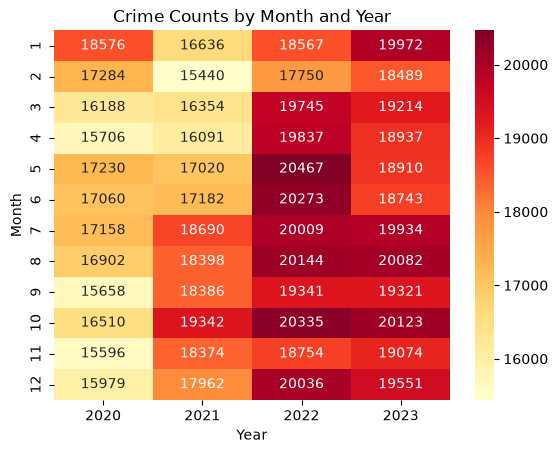

In [61]:
sns.heatmap(monthly_crimes, annot=True, fmt="d", cmap="YlOrRd")
plt.title("Crime Counts by Month and Year")
plt.show()